# Thermodynamic boundary checks

**Known inputs for every point:** $T(0^-)$ and $n_B(0^-)$.  
**Prescribed:** $T(0^+)$.  
**Unknown only at $0^+$:** $\mu_B(0^+)$ and $\mu_K(0^+)$.

The common point solve uses two equations:

$$
P_{\rm QM}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)
=P_{\rm PNM}\!\left(n_B(0^-),T(0^-)\right),
$$

$$
\frac{h_{\rm QM}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)}
{n_{B,{\rm QM}}\!\left(\mu_B(0^+),\mu_K(0^+),T(0^+)\right)}
=\frac{h_{\rm PNM}\!\left(n_B(0^-),T(0^-)\right)}{n_B(0^-)}.
$$

It returns $\mu_B(0^+)$, $\mu_K(0^+)$, $n_s(0^+)$, and $a(0^+)=n_K(0^+)/n_B(0^+)$.  
The stable-neutron boundary is the zero set $\mu_K(0^+)=0$.  
The cold composition ceiling is the zero set $n_s(0^+)=0$, equivalently $\mu_s(0^+)=0$, where charge neutrality gives $a(0^+)=1$.

The upstream coordinates are inputs to each point solve; a boundary finder only samples different upstream points externally. No BVP, velocity, reaction rate, or diffusion coefficient enters either calculation.

In [8]:
from pathlib import Path
from functools import lru_cache
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, root_scalar
from tqdm import tqdm
from RMFsolver import phase_velocity as pv

@lru_cache(maxsize=4096)
def upstream(T_0minus, nB_0minus):
    return pv._validated_pnm_state_from_nB(float(nB_0minus), float(T_0minus))

def matching_residuals(muB_0plus, muK_0plus, T_0minus, nB_0minus, T_0plus):
    state = upstream(T_0minus, nB_0minus)
    P = pv.PQM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS, upB=UPB)
    h = pv.hQM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS, upB=UPB)
    nB = pv.nB_QM(muB_0plus, muK_0plus, B14, T_0plus, ms=MS, upB=UPB)
    return np.array([(P-state["P_0minus"])/max(abs(state["P_0minus"]), 1.),
                     (h/nB-state["h_over_nB_0minus"])/state["h_over_nB_0minus"]])

def quark_outputs(muB_0plus, muK_0plus, T_0plus):
    state = pv._quark_uds_state(muB_0plus, muK_0plus, T_0plus, ms=MS, upB=UPB)
    nB, nK, n_s = state["nB"], state["nK"], state["species"]["n_s"]
    return {"n_s": n_s, "nB": nB, "nK": nK, "a": nK/nB,
            "mu_s": state["chemical_potentials"]["mu_s"]}

def checked(solution, tolerance=1e-8):
    if (not solution.success or not np.all(np.isfinite(solution.fun))
            or np.max(np.abs(solution.fun)) > tolerance):
        raise RuntimeError(f"No verified root: {solution.message}; residual={solution.fun}")
    return solution.x

def solve_0plus_state(T_0minus, nB_0minus, T_0plus=0.1, guess=(1100., 50.)):
    """The upstream pair is fixed; solve only for (muB_0plus, muK_0plus)."""
    sol = least_squares(
        lambda z: matching_residuals(1000*z[0], 100*z[1], T_0minus, nB_0minus, T_0plus),
        [guess[0]/1000, guess[1]/100], bounds=([0.3, 0], [3, 20]),
        xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=120)
    muB, muK = 1000*checked(sol)[0], 100*checked(sol)[1]
    out = quark_outputs(muB, muK, T_0plus)
    return {"muB_0plus": float(muB), "muK_0plus": float(muK),
            "n_s_0plus": float(out["n_s"]), "nB_0plus": float(out["nB"]),
            "nK_0plus": float(out["nK"]), "a_0plus": float(out["a"])}

def stable_boundary_at_T(T_0minus, T_0plus, guess):
    """At fixed T_0minus, locate the external density coordinate where muK_0plus=0."""
    sol = least_squares(
        lambda z: matching_residuals(1000*z[1], 0., T_0minus, z[0]*N0, T_0plus),
        [guess[0], guess[1]/1000], bounds=([1., 0.3], [5.5, 3.]),
        diff_step=1e-4, xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=120)
    n_over, muB_scaled = checked(sol)
    return {"T_0minus_MeV": float(T_0minus), "nB_0minus_over_n0": float(n_over),
            "muB_0plus_MeV": float(1000*muB_scaled)}

def A_boundary_at_T(T_0minus, T_cold, guess):
    """At fixed T_0minus, locate the external density coordinate where n_s=0."""
    def residual(z):
        n_over, muB_scaled, muK_scaled = z
        muB, muK = 1000*muB_scaled, 100*muK_scaled
        match = matching_residuals(muB, muK, T_0minus, n_over*N0, T_cold)
        return np.r_[match, quark_outputs(muB, muK, T_cold)["mu_s"]/1000]
    sol = least_squares(residual, [guess[0], guess[1]/1000, guess[2]/100],
                        bounds=([1., 0.3, 0.], [5.5, 3., 20.]), diff_step=1e-4,
                        xtol=1e-11, ftol=1e-11, gtol=1e-11, max_nfev=160)
    n_over, muB_scaled, muK_scaled = checked(sol)
    muB, muK = 1000*muB_scaled, 100*muK_scaled
    out = quark_outputs(muB, muK, T_cold)
    return {"T_0minus_MeV": float(T_0minus), "nB_0minus_over_n0": float(n_over),
            "muB_cold_MeV": float(muB), "muK_cold_MeV": float(muK),
            "n_s_over_nB": float(out["n_s"]/out["nB"]), "a_cold": float(out["a"])}

## Are the two matching contours independent?

For one fixed upstream input, first solve the common point problem and prescribe its resulting $\mu_B(0^+)$. In the $\bigl(\mu_K(0^+),T(0^+)\bigr)$ plane, solve each matching condition separately for its required temperature. Exact overlap would make their temperature difference identically zero; their isolated crossing is the common $0^+$ solution.

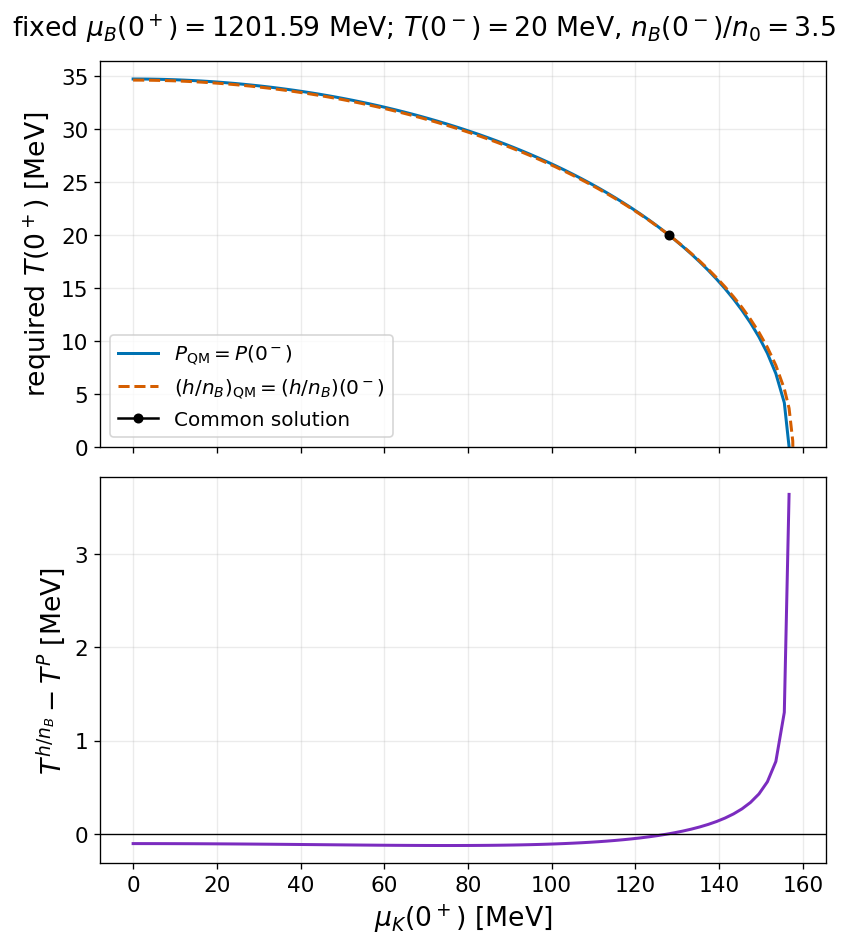

In [2]:
# Tunable plotting parameters
SOURCE = Path("new_paper_calculations/26-08-21/T0plus0p1-domain.npy")
COMPARISON_T_0MINUS_MEV = 20.
COMPARISON_NB_0MINUS_OVER_N0 = 3.5
COMPARISON_T_0PLUS_MEV = 20.
MU_K_ZERO_SCAN_RANGE_MEV = (0., 400.)
MU_K_ZERO_SCAN_POINTS = 401
MU_K_POINT_COUNT = 80
MU_K_WINDOW_PADDING_MEV = 2.
TEMPERATURE_BRACKET_MEV = (0., 80.)
TEMPERATURE_BRACKET_POINTS = 161
TEMPERATURE_AXIS_LIMIT_MEV = (0., None)
ROOT_RESIDUAL_TOLERANCE = 1.e-10
FIGURE_SIZE = (7., 8.)
DPI = 120
FONT_SIZE, TICK_FONT_SIZE, LEGEND_FONT_SIZE = 16, 13, 12
PRESSURE_COLOR, ENTHALPY_COLOR, DIFFERENCE_COLOR = "#0072B2", "#D55E00", "#7B2CBF"
PRESSURE_STYLE, ENTHALPY_STYLE, INTERSECTION_MARKER = "-", "--", "o"
LINE_WIDTH, ZERO_LINE_WIDTH, MARKER_SIZE = 1.8, 0.8, 5.
GRID_ALPHA = 0.25

payload = np.load(SOURCE, allow_pickle=True).item()
B14, N0 = (payload["calibration"][k] for k in ("B14_MeV", "n0_MeV3"))
MS, UPB = payload["ms_MeV"], payload["upB"]
comparison_nB = COMPARISON_NB_0MINUS_OVER_N0*N0
intersection = solve_0plus_state(COMPARISON_T_0MINUS_MEV, comparison_nB,
                                 COMPARISON_T_0PLUS_MEV, guess=(1200., 160.))
fixed_muB = intersection["muB_0plus"]

def required_temperature(muK, residual_index):
    grid = np.linspace(*TEMPERATURE_BRACKET_MEV, TEMPERATURE_BRACKET_POINTS)
    values = [matching_residuals(fixed_muB, muK, COMPARISON_T_0MINUS_MEV,
              comparison_nB, T)[residual_index] for T in grid]
    for lo, hi, flo, fhi in zip(grid[:-1], grid[1:], values[:-1], values[1:]):
        if abs(flo) < ROOT_RESIDUAL_TOLERANCE or flo*fhi < 0:
            return float(lo if abs(flo) < ROOT_RESIDUAL_TOLERANCE else root_scalar(
                lambda T: matching_residuals(fixed_muB, muK, COMPARISON_T_0MINUS_MEV,
                comparison_nB, T)[residual_index], bracket=(lo, hi), method="brentq").root)
    return np.nan

def zero_temperature_muK(residual_index):
    grid = np.linspace(*MU_K_ZERO_SCAN_RANGE_MEV, MU_K_ZERO_SCAN_POINTS)
    values = [matching_residuals(fixed_muB, muK, COMPARISON_T_0MINUS_MEV,
              comparison_nB, 0.)[residual_index] for muK in grid]
    for lo, hi, flo, fhi in zip(grid[:-1], grid[1:], values[:-1], values[1:]):
        if abs(flo) < ROOT_RESIDUAL_TOLERANCE or flo*fhi < 0:
            return float(lo if abs(flo) < ROOT_RESIDUAL_TOLERANCE else root_scalar(
                lambda muK: matching_residuals(fixed_muB, muK, COMPARISON_T_0MINUS_MEV,
                comparison_nB, 0.)[residual_index], bracket=(lo, hi), method="brentq").root)
    raise RuntimeError(f"No T(0+)=0 endpoint for residual {residual_index}")

muK_zero_pressure = zero_temperature_muK(0)
muK_zero_enthalpy = zero_temperature_muK(1)
muK_stop = max(muK_zero_pressure, muK_zero_enthalpy)+MU_K_WINDOW_PADDING_MEV
muK_axis = np.unique(np.r_[np.linspace(MU_K_ZERO_SCAN_RANGE_MEV[0], muK_stop, MU_K_POINT_COUNT),
                           muK_zero_pressure, muK_zero_enthalpy, intersection["muK_0plus"]])
T_pressure = np.array([required_temperature(x, 0) for x in muK_axis])
T_enthalpy = np.array([required_temperature(x, 1) for x in muK_axis])
temperature_difference = T_enthalpy-T_pressure

fig, axes = plt.subplots(2, 1, figsize=FIGURE_SIZE, dpi=DPI, sharex=True)
axes[0].plot(muK_axis, T_pressure, color=PRESSURE_COLOR, ls=PRESSURE_STYLE,
             lw=LINE_WIDTH, label=r"$P_{\rm QM}=P(0^-)$")
axes[0].plot(muK_axis, T_enthalpy, color=ENTHALPY_COLOR, ls=ENTHALPY_STYLE,
             lw=LINE_WIDTH, label=r"$(h/n_B)_{\rm QM}=(h/n_B)(0^-)$")
axes[0].plot(intersection["muK_0plus"], COMPARISON_T_0PLUS_MEV,
             marker=INTERSECTION_MARKER, ms=MARKER_SIZE, color="black", label="Common solution")
axes[0].set_ylim(*TEMPERATURE_AXIS_LIMIT_MEV)
axes[0].set_ylabel(r"required $T(0^+)$ [MeV]", fontsize=FONT_SIZE)
axes[0].legend(fontsize=LEGEND_FONT_SIZE)
axes[1].plot(muK_axis, temperature_difference, color=DIFFERENCE_COLOR, lw=LINE_WIDTH)
axes[1].axhline(0., color="black", lw=ZERO_LINE_WIDTH)
axes[1].set_xlabel(r"$\mu_K(0^+)$ [MeV]", fontsize=FONT_SIZE)
axes[1].set_ylabel(r"$T^{h/n_B}-T^P$ [MeV]", fontsize=FONT_SIZE)
for ax in axes:
    ax.tick_params(labelsize=TICK_FONT_SIZE)
    ax.grid(alpha=GRID_ALPHA)
fig.suptitle(rf"fixed $\mu_B(0^+)={fixed_muB:.2f}$ MeV; "
             rf"$T(0^-)={COMPARISON_T_0MINUS_MEV:g}$ MeV, "
             rf"$n_B(0^-)/n_0={COMPARISON_NB_0MINUS_OVER_N0:g}$", fontsize=FONT_SIZE)
fig.tight_layout()
plt.show()


## Calculate and compare the zero sets

The first solve uses the prescribed physical $T(0^+)$ and locates $\mu_K(0^+)=0$. The second uses the same exact matching equations at the cluster cold temperature and locates $n_s(0^+)=0$ through the numerically better-conditioned equivalent residual $\mu_s(0^+)=0$. The returned $n_s/n_B$ and $a$ verify the physical ceiling directly.

The collaborator CSVs supply both boundaries as $T(0^-)$, $\mu_B(0^-)$, and $\mu_B(0^+)$. Their $\mu_B(0^-)$ values are converted to $n_B(0^-)/n_0$ with the same PNM EoS before comparison.

In [3]:
# Tunable calculation parameters
STABLE_T_0PLUS_MEV = 0.1
A_COLD_T_MEV = 1.0e-3
STABLE_GUESS = (3.0, 1190.)
A_GUESS = (5.298, 1053., 587.)
COLLABORATOR_STABLE_SOURCE = Path("local_analysis_results/FL26-2/mub_muq_along_lower_grey_region_of_tminus.csv")
COLLABORATOR_A_SOURCE = Path("local_analysis_results/FL26-2/mub_upper_grey_region_boundary_tMeV.csv")
DIRECT_POINT_DENSITY_FACTOR = 1.5
semi = payload["boundary_diagnostics"]["semi_analytic"]
stable_saved = np.array(sorted((r["nB_over_n0"], r["T_MeV"])
    for r in semi["gap_curve_records_by_T0plus"][STABLE_T_0PLUS_MEV]
    if r["status"] == "success"))
A_saved = np.array([(r["nB_over_n0"], r["T_MeV"])
    for r in semi["A_curve_records"] if r["status"] == "root"])
direct_point_count = int(np.ceil(len(stable_saved)*DIRECT_POINT_DENSITY_FACTOR))
stable_direct_temperatures = np.linspace(stable_saved[:, 1].min(), stable_saved[:, 1].max(), direct_point_count)
A_path = np.linspace(0., len(A_saved)-1., direct_point_count)
A_direct_seeds = np.column_stack([np.interp(A_path, np.arange(len(A_saved)), A_saved[:, j]) for j in (0, 1)])
started = perf_counter()
stable_rows, guess = [], STABLE_GUESS
for T in tqdm(stable_direct_temperatures, desc=r"$\mu_K(0^+)=0$", unit="point"):
    row = stable_boundary_at_T(float(T), STABLE_T_0PLUS_MEV, guess)
    stable_rows.append(row)
    guess = (row["nB_0minus_over_n0"], row["muB_0plus_MeV"])

A_rows, guess = [], A_GUESS
for n_seed, T in tqdm(A_direct_seeds, desc=r"$n_s(0^+)=0$", unit="point"):
    guess = (float(n_seed), guess[1], guess[2])
    row = A_boundary_at_T(float(T), A_COLD_T_MEV, guess)
    A_rows.append(row)
    guess = (row["nB_0minus_over_n0"], row["muB_cold_MeV"], row["muK_cold_MeV"])

stable_direct = np.array([(r["nB_0minus_over_n0"], r["T_0minus_MeV"]) for r in stable_rows])
A_direct = np.array([(r["nB_0minus_over_n0"], r["T_0minus_MeV"]) for r in A_rows])
def load_collaborator_boundary(source):
    table = pd.read_csv(source, header=None, names=["T_0minus_MeV", "Mathematica_rules"])
    for column, label in (("muB_0minus_MeV", "nuc"), ("muB_0plus_MeV", "quark")):
        table[column] = table["Mathematica_rules"].str.extract(
            rf"mub\${label}\$\d+\s*->\s*([-+0-9.eE]+)", expand=False).astype(float)
    table["nB_0minus_over_n0"] = [float(pv.nB_NM(muB, T))/N0 for T, muB in zip(
        table["T_0minus_MeV"], table["muB_0minus_MeV"])]
    return table, table[["nB_0minus_over_n0", "T_0minus_MeV"]].to_numpy()
collaborator_stable_table, collaborator_stable = load_collaborator_boundary(COLLABORATOR_STABLE_SOURCE)
collaborator_A_table, collaborator_A = load_collaborator_boundary(COLLABORATOR_A_SOURCE)
print(f"Finished {len(stable_rows)+len(A_rows)} roots in {perf_counter()-started:.1f} s")
print(f"Loaded {len(collaborator_stable)} stable and {len(collaborator_A)} A=1 collaborator points")
display(pd.DataFrame(A_rows))


$\mu_K(0^+)=0$:   0%|          | 0/18 [00:00<?, ?point/s]


$\mu_K(0^+)=0$:   6%|▌         | 1/18 [00:01<00:20,  1.23s/point]


$\mu_K(0^+)=0$:  11%|█         | 2/18 [00:06<00:54,  3.42s/point]


$\mu_K(0^+)=0$:  17%|█▋        | 3/18 [00:10<01:00,  4.03s/point]


$\mu_K(0^+)=0$:  22%|██▏       | 4/18 [00:16<01:03,  4.57s/point]

...


$n_s(0^+)=0$:  94%|█████████▍| 17/18 [01:09<00:03,  3.80s/point]


$n_s(0^+)=0$: 100%|██████████| 18/18 [01:11<00:00,  3.46s/point]


$n_s(0^+)=0$: 100%|██████████| 18/18 [01:11<00:00,  3.98s/point]

Finished 36 roots in 201.7 s
Loaded 11 stable and 13 A=1 collaborator points


,T_0minus_MeV,nB_0minus_over_n0,muB_cold_MeV,muK_cold_MeV,n_s_over_nB,a_cold
0,0.000000,5.297929,1052.737158,586.907983,1.110018e-26,1.0
1,10.567406,5.281894,1051.575935,586.260593,0.000000e+00,1.0
2,21.072209,5.233815,1048.094823,584.319850,5.624164e-27,1.0
3,31.501888,5.153276,1042.266741,581.070656,5.719040e-27,1.0
4,41.671808,5.041345,1034.176547,576.560319,1.756293e-26,1.0
5,51.648753,4.896557,1023.734888,570.739024,0.000000e+00,1.0
6,61.333453,4.718553,1010.948723,563.610652,0.000000e+00,1.0
7,70.462759,4.510831,996.127540,555.347744,6.551110e-27,1.0
8,79.196287,4.266780,978.903994,545.745502,-6.903025e-27,1.0
9,87.203525,3.991018,959.776061,535.081552,7.324028e-27,1.0


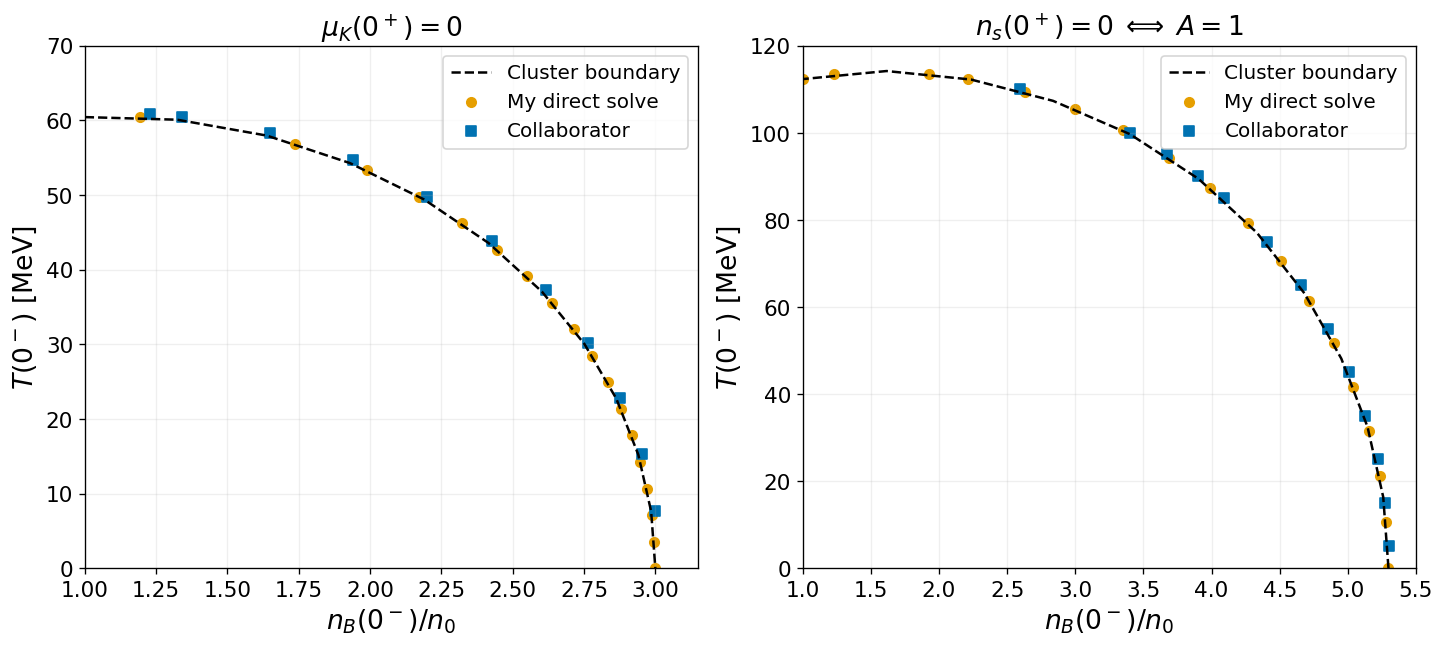

In [4]:
# Tunable plotting parameters
FIGURE_SIZE = (12., 5.5)
DPI = 120
FONT_SIZE, TICK_FONT_SIZE, LEGEND_FONT_SIZE = 16, 13, 12
CLUSTER_COLOR = "black"
OURS_COLOR = "#E69F00"
COLLABORATOR_COLOR = "#0072B2"
CLUSTER_STYLE = "--"
OURS_MARKER = "o"
COLLABORATOR_MARKER = "s"
LINE_WIDTH, MARKER_SIZE = 1.5, 32.
STABLE_X_LIMITS, STABLE_Y_LIMITS = (1., 3.15), (0., 70.)
A_X_LIMITS, A_Y_LIMITS = (1., 5.5), (0., 120.)
GRID_ALPHA = 0.2

fig, axes = plt.subplots(1, 2, figsize=FIGURE_SIZE, dpi=DPI)
panels = ((stable_saved, stable_direct, collaborator_stable,
           r"$\mu_K(0^+)=0$", STABLE_X_LIMITS, STABLE_Y_LIMITS),
          (A_saved, A_direct, collaborator_A,
           r"$n_s(0^+)=0\;\Longleftrightarrow\;A=1$", A_X_LIMITS, A_Y_LIMITS))
for ax, (cluster, ours, collaborator, title, xlim, ylim) in zip(axes, panels):
    ax.plot(*cluster.T, color=CLUSTER_COLOR, ls=CLUSTER_STYLE, lw=LINE_WIDTH,
            label="Cluster boundary")
    ax.scatter(*ours.T, color=OURS_COLOR, marker=OURS_MARKER, s=MARKER_SIZE,
               label="My direct solve")
    if collaborator is not None:
        ax.scatter(*collaborator.T, color=COLLABORATOR_COLOR,
                   marker=COLLABORATOR_MARKER, s=MARKER_SIZE,
                   label="Collaborator")
    ax.set(xlim=xlim, ylim=ylim)
    ax.set_xlabel(r"$n_B(0^-)/n_0$", fontsize=FONT_SIZE)
    ax.set_ylabel(r"$T(0^-)$ [MeV]", fontsize=FONT_SIZE)
    ax.set_title(title, fontsize=FONT_SIZE)
    ax.tick_params(labelsize=TICK_FONT_SIZE)
    ax.grid(alpha=GRID_ALPHA)
    ax.legend(fontsize=LEGEND_FONT_SIZE)
fig.tight_layout()
plt.show()